In [1]:
!pip -q install -U transformers peft accelerate bitsandbytes datasets evaluate rouge_score bert_score kagglehub sentencepiece ipywidgets

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 120.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 61.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 37.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conf

## 1. Config

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os, re, glob, gc, json, shutil, warnings
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # less fragmentation
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from transformers import set_seed
warnings.filterwarnings("ignore")

MODEL_ID       = "nvidia/Llama-3.1-Nemotron-Nano-4B-v1.1"
KAGGLE_DATASET = "nileshmalode1/samsum-dataset"   # change if your Kaggle slug differs
N_TRAIN  = 8000      # training subset size
N_VAL    = 100       # small val set used during training
N_TEST   = None      # None = full test set (819). Set e.g. 200 for a quick run
MAX_LEN  = 512       # max tokens (prompt + summary); SAMSum rarely exceeds ~400
EPOCHS   = 1         # 1 epoch on 8k is usually enough; try 2 if scores plateau low
EVAL_BS  = 4        # smallest-memory setting for free-tier T4 (raise if you have headroom)
SEED     = 42
USE_DRIVE     = True    # save everything to Google Drive so nothing is lost on disconnect
FORCE_RETRAIN = False   # False: if a saved adapter exists in OUT_DIR, load it and SKIP training
OUT_DIR  = "/content/drive/MyDrive/nemotron_samsum" if USE_DRIVE else "/content/nemotron_samsum"
# --------------------

set_seed(SEED)
assert torch.cuda.is_available(), "No GPU. Runtime -> Change runtime type -> GPU"
print("GPU:", torch.cuda.get_device_name(0))
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
USE_BF16 = torch.cuda.get_device_capability()[0] >= 8      # A100/L4 -> bf16, T4 -> fp16
DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
print("Precision:", "bf16" if USE_BF16 else "fp16")

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(OUT_DIR, exist_ok=True)
ADAPTER_DIR = f"{OUT_DIR}/adapter"
HAVE_ADAPTER = os.path.exists(f"{ADAPTER_DIR}/adapter_config.json") and not FORCE_RETRAIN
print("Saved adapter found -> training will be skipped" if HAVE_ADAPTER else "No saved adapter -> will train")

GPU: NVIDIA A100-SXM4-40GB
VRAM: 42.4 GB
Precision: bf16
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
No saved adapter -> will train


## Utilities: free GPU memory / restart / disconnect

In [7]:
def free_mem():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.ipc_collect()
    print(f"GPU allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB | reserved: {torch.cuda.memory_reserved()/1e9:.2f} GB")
free_mem()

# --- Optional, run manually when needed ---
# Hard restart of the kernel (clears ALL GPU memory; then re-run the cells from the top):
# os.kill(os.getpid(), 9)

# Release the Colab GPU and disconnect the runtime (frees your free-tier quota when you are done):
# from google.colab import runtime; runtime.unassign()

GPU allocated: 0.00 GB | reserved: 0.00 GB


## 2. Load SAMSum straight from Kaggle (auto-download + auto-unzip)

In [8]:
import kagglehub

def kaggle_download(slug):
    try:  # Colab secrets, if set
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    except Exception:
        pass
    try:
        return kagglehub.dataset_download(slug)   # downloads AND extracts
    except Exception as e:
        print("Download failed (%s). Logging in..." % type(e).__name__)
        kagglehub.login()                          # prompts for username + key
        return kagglehub.dataset_download(slug)

def read_any(p):
    if p.endswith(".csv"):   return pd.read_csv(p)
    if p.endswith(".jsonl"): return pd.read_json(p, lines=True)
    try:    return pd.read_json(p)
    except ValueError: return pd.read_json(p, lines=True)

def norm(df):
    df = df.copy()
    df.columns = [c.lower().strip() for c in df.columns]
    if not {"dialogue", "summary"} <= set(df.columns):
        raise ValueError("Expected 'dialogue' and 'summary' columns, found: %s" % list(df.columns))
    df = df[["dialogue", "summary"]].dropna()
    for c in ["dialogue", "summary"]:
        df[c] = df[c].astype(str).str.replace("\r\n", "\n").str.strip()
    return df[(df.dialogue != "") & (df.summary != "")].reset_index(drop=True)

def load_from_kaggle(slug):
    root = kaggle_download(slug)
    files = [f for ext in ("csv", "json", "jsonl") for f in glob.glob(f"{root}/**/*.{ext}", recursive=True)]
    print("Files found:", [os.path.relpath(f, root) for f in files])
    splits = {}
    for f in sorted(files):
        n = os.path.basename(f).lower()
        key = "train" if "train" in n else "val" if ("val" in n or "dev" in n) else "test" if "test" in n else None
        if key and key not in splits:
            splits[key] = norm(read_any(f))
    if "train" not in splits or "test" not in splits:
        raise RuntimeError("Could not find train/test files, got: %s" % list(splits))
    return splits

try:
    splits = load_from_kaggle(KAGGLE_DATASET)
except Exception as e:
    print("Kaggle load failed:", e, "\nFalling back to HF copy of SAMSum...")
    from datasets import load_dataset
    ds = load_dataset("knkarthick/samsum")
    splits = {"train": norm(ds["train"].to_pandas()), "val": norm(ds["validation"].to_pandas()),
              "test": norm(ds["test"].to_pandas())}

train_df, test_df = splits["train"], splits["test"]
if "val" in splits:
    val_df = splits["val"]
else:
    val_df = train_df.sample(N_VAL, random_state=SEED)
    train_df = train_df.drop(val_df.index)

train_df = train_df.sample(n=min(N_TRAIN, len(train_df)), random_state=SEED).reset_index(drop=True)
val_df   = val_df.sample(n=min(N_VAL, len(val_df)), random_state=SEED).reset_index(drop=True)
if N_TEST:
    test_df = test_df.sample(n=min(N_TEST, len(test_df)), random_state=SEED)
test_df = test_df.reset_index(drop=True)

print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")
train_df.head(2)

Download failed (KaggleApiHTTPError). Logging in...


Kaggle load failed: 403 Client Error.

You don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent. 
Falling back to HF copy of SAMSum...


README.md:   0%|          | 0.00/4.36k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/9.26M [00:00<?, ?B/s]

validation.csv:   0%|          | 0.00/504k [00:00<?, ?B/s]

...

Generating train split:   0%|          | 0/14731 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/818 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/819 [00:00<?, ? examples/s]

train=8000  val=100  test=819


,dialogue,summary
0,Violet: hi! i came across this Austin's articl...,Violet sent Claire Austin's article.
1,"Mel: Right, it's time I bought some Christmas ...",Mel bought Christmas presents while Evie keeps...


## 3. Tokenizer + chat-format preprocessing (loss on the summary only)

In [9]:
from transformers import AutoTokenizer
from datasets import Dataset

tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

EOT_ID = tok.convert_tokens_to_ids("<|eot_id|>")
if EOT_ID is None or EOT_ID == tok.unk_token_id:
    EOT_ID = tok.eos_token_id
EOS_IDS = list({EOT_ID, tok.eos_token_id})

SYSTEM = "detailed thinking off"   # Nemotron reasoning toggle: no <think> blocks

def build_prompt(dialogue):
    msgs = [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": "Summarize the following dialogue in one or two sentences.\n\n" + dialogue}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def encode(dialogue, summary):
    p = tok(build_prompt(dialogue), add_special_tokens=False)["input_ids"]
    a = tok(summary, add_special_tokens=False)["input_ids"] + [EOT_ID]
    return {"input_ids": p + a, "labels": [-100] * len(p) + a}

def make_ds(df):
    rows = [encode(d, s) for d, s in zip(df.dialogue, df.summary)]
    rows = [r for r in rows if len(r["input_ids"]) <= MAX_LEN]
    return Dataset.from_list(rows)

train_ds, val_ds = make_ds(train_df), make_ds(val_df)
print(f"kept train={len(train_ds)}  val={len(val_ds)}  (dropped rows longer than {MAX_LEN} tokens)")

ex = train_ds[0]
print("\n--- sample (prompt part) ---")
print(tok.decode([t for t, l in zip(ex["input_ids"], ex["labels"]) if l == -100]))
print("--- target ---")
print(tok.decode([l for l in ex["labels"] if l != -100]))

config.json:   0%|          | 0.00/910 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.6k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


kept train=7860  val=96  (dropped rows longer than 512 tokens)

--- sample (prompt part) ---
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

detailed thinking off<|eot_id|><|start_header_id|>user<|end_header_id|>

Summarize the following dialogue in one or two sentences.

Violet: hi! i came across this Austin's article and i thought that you might find it interesting
Violet: <file_other>
Claire: Hi! :) Thanks, but I've already read it. :)
Claire: But thanks for thinking about me :)<|eot_id|><|start_header_id|>assistant<|end_header_id|>


--- target ---
Violet sent Claire Austin's article.<|eot_id|>


### Visual: what the model sees during training

## 4. Load model in 4-bit + attach LoRA

In [11]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=DTYPE)
def load_base(trust):
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb,
                                                device_map={"": 0}, torch_dtype=DTYPE,
                                                trust_remote_code=trust)
try:
    model = load_base(False)
except ValueError:
    model = load_base(True)

# Lighter than prepare_model_for_kbit_training (which upcasts embeddings/lm_head to fp32, ~3GB extra)
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.enable_input_require_grads()
lora_cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none",
                      target_modules="all-linear", task_type="CAUSAL_LM")
if HAVE_ADAPTER:
    from peft import PeftModel
    model = PeftModel.from_pretrained(model, ADAPTER_DIR)   # trained adapter -> no retraining needed
    print("Loaded saved adapter from", ADAPTER_DIR)
else:
    model = get_peft_model(model, lora_cfg)
model.print_trainable_parameters()
print(f"GPU mem used: {torch.cuda.memory_allocated()/1e9:.1f} GB")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/155 [00:00<?, ?B/s]

trainable params: 30,408,704 || all params: 4,543,155,200 || trainable%: 0.6693
GPU mem used: 3.6 GB


## 5. Generation + metrics helpers

In [12]:
from tqdm.auto import tqdm
import evaluate

rouge = evaluate.load("rouge")
bertscore = evaluate.load("bertscore")

def clean(t):
    return re.sub(r"<think>.*?</think>", "", t, flags=re.S).strip()

@torch.no_grad()
def generate(dialogues, bs=EVAL_BS, max_new_tokens=100, num_beams=1):
    model.eval(); model.config.use_cache = True
    tok.padding_side = "left"
    prompts = [build_prompt(d) for d in dialogues]
    order = np.argsort([len(p) for p in prompts])[::-1]      # longest first -> fewer OOM surprises
    outs = [None] * len(prompts)
    for i in tqdm(range(0, len(order), bs), desc="generating"):
        idx = order[i:i + bs]
        enc = tok([prompts[j] for j in idx], return_tensors="pt", padding=True,
                  add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             num_beams=num_beams, temperature=None, top_p=None,
                             pad_token_id=tok.pad_token_id, eos_token_id=EOS_IDS)
        texts = tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        for j, t in zip(idx, texts):
            outs[j] = clean(t)
    return outs

def score(preds, refs):
    r = rouge.compute(predictions=preds, references=refs, use_stemmer=True)
    b = bertscore.compute(predictions=preds, references=refs, lang="en", batch_size=8)
    return {"ROUGE-1": r["rouge1"] * 100, "ROUGE-2": r["rouge2"] * 100,
            "ROUGE-L": r["rougeL"] * 100, "BERTScore-F1": float(np.mean(b["f1"])) * 100,
            "Avg words": float(np.mean([len(p.split()) for p in preds]))}

## 6. Zero-shot baseline (base model, adapter disabled)

In [13]:
test_dialogues, test_refs = test_df.dialogue.tolist(), test_df.summary.tolist()

def cached(path, fn):
    """Reuse saved predictions if they match this test set; otherwise generate and save."""
    if os.path.exists(path):
        c = json.load(open(path))
        if len(c) == len(test_dialogues):
            print("Loaded cached predictions:", os.path.basename(path)); return c
    out = fn(); json.dump(out, open(path, "w")); return out

def _base():
    with model.disable_adapter():
        return generate(test_dialogues)

base_preds = cached(f"{OUT_DIR}/preds_base.json", _base)
base_scores = score(base_preds, test_refs)
print({k: round(v, 2) for k, v in base_scores.items()})
gc.collect(); torch.cuda.empty_cache()

generating:   0%|          | 0/205 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'ROUGE-1': np.float64(29.15), 'ROUGE-2': np.float64(7.55), 'ROUGE-L': np.float64(20.9), 'BERTScore-F1': 87.96, 'Avg words': 47.17}


## 7. Train (QLoRA)

In [14]:
from transformers import Trainer, TrainingArguments

def collate(batch):
    m = max(len(x["input_ids"]) for x in batch)
    ids  = [x["input_ids"] + [tok.pad_token_id] * (m - len(x["input_ids"])) for x in batch]
    lab  = [x["labels"]    + [-100] * (m - len(x["labels"])) for x in batch]
    att  = [[1] * len(x["input_ids"]) + [0] * (m - len(x["input_ids"])) for x in batch]
    return {"input_ids": torch.tensor(ids), "labels": torch.tensor(lab), "attention_mask": torch.tensor(att)}

total_steps = -(-len(train_ds) // 16) * EPOCHS
WARMUP_STEPS = max(1, int(0.03 * total_steps))   # ~3% warmup (works across transformers versions)

args = TrainingArguments(
    output_dir=f"{OUT_DIR}/ckpt",
    per_device_train_batch_size=1, gradient_accumulation_steps=16,   # effective batch 16, minimum memory
    per_device_eval_batch_size=2,
    num_train_epochs=EPOCHS, learning_rate=2e-4,
    lr_scheduler_type="cosine", warmup_steps=WARMUP_STEPS, weight_decay=0.0,
    optim="paged_adamw_8bit", max_grad_norm=0.3,
    bf16=USE_BF16, fp16=not USE_BF16,
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=20, eval_strategy="steps", eval_steps=100,
    save_strategy="steps", save_steps=100, save_total_limit=2,
    report_to="none", remove_unused_columns=False, seed=SEED,
)
LOG_PATH = f"{OUT_DIR}/log_history.json"
if HAVE_ADAPTER:
    print("Saved adapter loaded -> skipping training")
    log_history = json.load(open(LOG_PATH)) if os.path.exists(LOG_PATH) else []
else:
    model.config.use_cache = False
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate)
    ckpts = glob.glob(f"{OUT_DIR}/ckpt/checkpoint-*")
    if ckpts:
        print("Resuming from latest checkpoint in", OUT_DIR)
    trainer.train(resume_from_checkpoint=True if ckpts else None)   # auto-resume after a disconnect
    log_history = trainer.state.log_history
    # save immediately so a later error or disconnect can't lose the trained model
    model.save_pretrained(ADAPTER_DIR); tok.save_pretrained(ADAPTER_DIR)
    json.dump(log_history, open(LOG_PATH, "w"))
    if os.path.exists(f"{OUT_DIR}/preds_ft.json"): os.remove(f"{OUT_DIR}/preds_ft.json")   # stale after retraining
    print("Adapter saved to", ADAPTER_DIR)

Step,Training Loss,Validation Loss
100,1.333097,1.308986
200,1.365913,1.274157
300,1.271706,1.241346
400,1.262045,1.222612


Step,Training Loss,Validation Loss
100,1.333097,1.308986
200,1.365913,1.274157
300,1.271706,1.241346
400,1.262045,1.222612
492,1.257198,1.219198


Adapter saved to /content/drive/MyDrive/nemotron_samsum/adapter


## 8. Evaluate the fine-tuned model on the test set

In [15]:
gc.collect(); torch.cuda.empty_cache()
ft_preds = cached(f"{OUT_DIR}/preds_ft.json", lambda: generate(test_dialogues))
ft_scores = score(ft_preds, test_refs)

res = pd.DataFrame({"Zero-shot base": base_scores, "Fine-tuned (QLoRA)": ft_scores}).T
res.loc["Improvement"] = res.loc["Fine-tuned (QLoRA)"] - res.loc["Zero-shot base"]
res = res.round(2)
display(res)

os.makedirs(OUT_DIR, exist_ok=True)
res.to_csv(f"{OUT_DIR}/results.csv")
pd.DataFrame({"dialogue": test_dialogues, "reference": test_refs,
              "base": base_preds, "finetuned": ft_preds}).to_csv(f"{OUT_DIR}/predictions.csv", index=False)

generating:   0%|          | 0/205 [00:00<?, ?it/s]

,ROUGE-1,ROUGE-2,ROUGE-L,BERTScore-F1,Avg words
Zero-shot base,29.15,7.55,20.90,87.96,47.17
Fine-tuned (QLoRA),51.34,26.66,42.92,92.57,17.21
Improvement,22.19,19.11,22.02,4.60,-29.97


## 8b. Visualizations

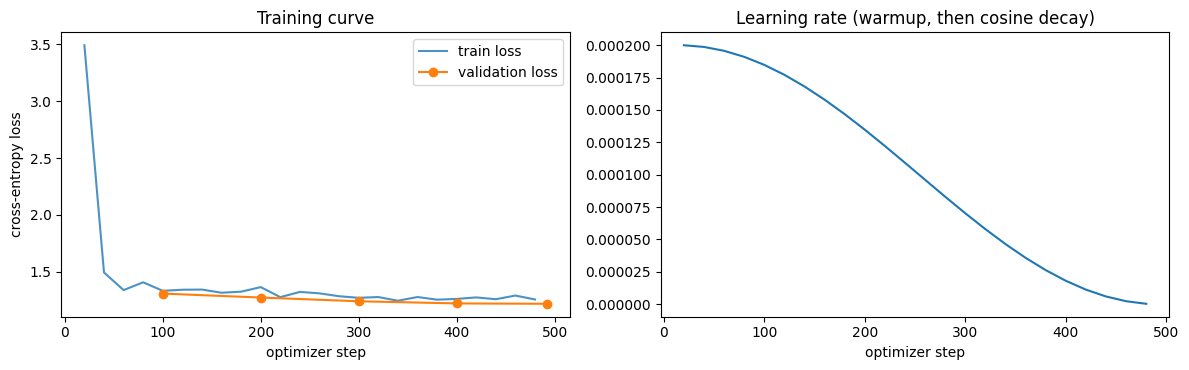

In [21]:
# 1) Training curve + learning-rate schedule
tr  = [(h["step"], h["loss"]) for h in log_history if "loss" in h]
ev  = [(h["step"], h["eval_loss"]) for h in log_history if "eval_loss" in h]
lrs = [(h["step"], h["learning_rate"]) for h in log_history if "learning_rate" in h]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
if tr: ax[0].plot(*zip(*tr), label="train loss", alpha=.8)
if ev: ax[0].plot(*zip(*ev), "o-", label="validation loss")
ax[0].set_xlabel("optimizer step"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title("Training curve"); ax[0].legend()
if lrs: ax[1].plot(*zip(*lrs))
ax[1].set_xlabel("optimizer step"); ax[1].set_title("Learning rate (warmup, then cosine decay)")
plt.tight_layout(); plt.show()

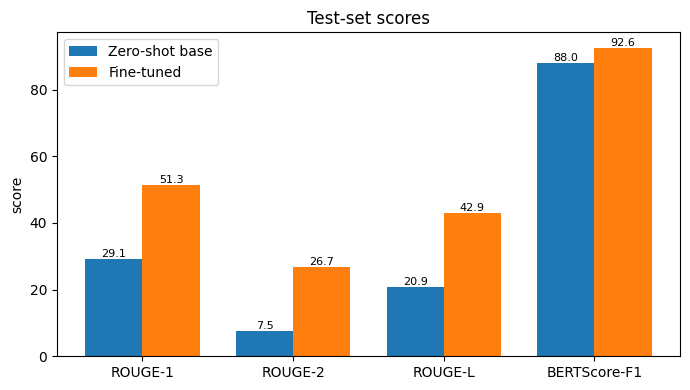

In [22]:
# 2) Base vs fine-tuned scores
metrics = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "BERTScore-F1"]
x, w = np.arange(len(metrics)), 0.38
fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - w/2, [base_scores[m] for m in metrics], w, label="Zero-shot base")
b2 = ax.bar(x + w/2, [ft_scores[m] for m in metrics], w, label="Fine-tuned")
for bars in (b1, b2): ax.bar_label(bars, fmt="%.1f", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(metrics); ax.set_ylabel("score"); ax.set_title("Test-set scores"); ax.legend()
plt.tight_layout(); plt.show()

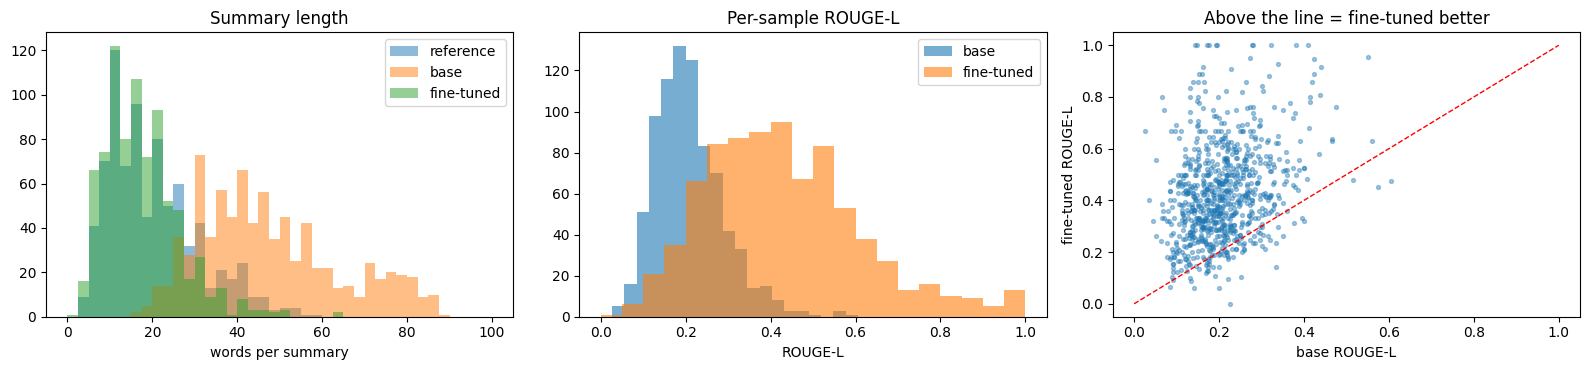

Fine-tuned beats base on 92% of test samples (ties 0%)


In [24]:
# 3) Summary length, per-sample ROUGE-L, and base-vs-fine-tuned scatter
ref_len  = [len(t.split()) for t in test_refs]
base_len = [len(t.split()) for t in base_preds]
ft_len   = [len(t.split()) for t in ft_preds]
rl_base = np.array(rouge.compute(predictions=base_preds, references=test_refs, use_stemmer=True, use_aggregator=False)["rougeL"])
rl_ft   = np.array(rouge.compute(predictions=ft_preds,   references=test_refs, use_stemmer=True, use_aggregator=False)["rougeL"])

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
bins = np.linspace(0, 100, 41)
ax[0].hist(ref_len, bins, alpha=.5, label="reference"); ax[0].hist(base_len, bins, alpha=.5, label="base"); ax[0].hist(ft_len, bins, alpha=.5, label="fine-tuned")
ax[0].set_xlabel("words per summary"); ax[0].set_title("Summary length"); ax[0].legend()
ax[1].hist(rl_base, bins=20, alpha=.6, label="base"); ax[1].hist(rl_ft, bins=20, alpha=.6, label="fine-tuned")
ax[1].set_xlabel("ROUGE-L"); ax[1].set_title("Per-sample ROUGE-L"); ax[1].legend()
ax[2].scatter(rl_base, rl_ft, s=8, alpha=.4); ax[2].plot([0, 1], [0, 1], "r--", lw=1)
ax[2].set_xlabel("base ROUGE-L"); ax[2].set_ylabel("fine-tuned ROUGE-L"); ax[2].set_title("Above the line = fine-tuned better")
plt.tight_layout(); plt.show()
print(f"Fine-tuned beats base on {np.mean(rl_ft > rl_base)*100:.0f}% of test samples "
      f"(ties {np.mean(rl_ft == rl_base)*100:.0f}%)")

## 9. Side-by-side samples (check for hallucinated names/facts)

In [17]:
for i in np.random.RandomState(0).choice(len(test_dialogues), 10, replace=False):
    print("=" * 90)
    print(test_dialogues[i])
    print("\nREFERENCE :", test_refs[i])
    print("BASE      :", base_preds[i])
    print("FINETUNED :", ft_preds[i])

Jane: I may be 10 min late. Sorry.
Alex: Ok. I'm by the left entrance.
Jane: The bus is running late. I've just passed the supermarket.
Alex: No worries. I'll be waiting for you.
Jane: Thnx
Alex: Did you remember to take the file with the xerox copies?
Jane: Yes. I hope it will be useful. It's quite a brick.
Alex: Hope so too
Jane: We'll do fine :-)
Alex: No other choice. Seems like it's our last chance of getting through to them.
Jane: Maybe they will be convinced after they've seen our materials.

REFERENCE : Jane will be about 10 minutes late. Alex is waiting at the left entrance and they are going to attend a meeting. This might be the last opportunity for Jane and Alex to get through to them.
BASE      : The dialogue between Jane and Alex involves a conversation where Jane apologizes for being potentially late and mentions she's passed the supermarket, while Alex provides her location and inquires about bringing a file with xerox copies, commenting on the brick (likely referring t

## 10. Test your own dialogue (base vs fine-tuned)

In [18]:
def compare(dialogue, max_new_tokens=100, num_beams=1):
    with model.disable_adapter():
        base = generate([dialogue], bs=1, max_new_tokens=max_new_tokens, num_beams=num_beams)[0]
    ft = generate([dialogue], bs=1, max_new_tokens=max_new_tokens, num_beams=num_beams)[0]
    print("BASE      :", base)
    print("FINETUNED :", ft)

CUSTOM_DIALOGUE = """Amy: Are we still on for dinner tonight?
Ben: Yes! 7pm at the Italian place?
Amy: Perfect. Can you book a table? I'll be late from work.
Ben: Sure, I'll book for 7:30 instead.
Amy: Thanks, see you there!"""
compare(CUSTOM_DIALOGUE)

generating:   0%|          | 0/1 [00:00<?, ?it/s]

generating:   0%|          | 0/1 [00:00<?, ?it/s]

BASE      : The dialogue illustrates Ben's adjustment to Amy's request by reserving a table a bit later than the initially proposed time to accommodate Amy's tardiness from work.
FINETUNED : Amy and Ben are meeting for dinner at 7:30 at the Italian place.


In [19]:
# Interactive box: paste any dialogue, click the button
import ipywidgets as w
from IPython.display import display, clear_output

box = w.Textarea(placeholder="Paste a dialogue, e.g.\nAmy: hi\nBen: hello", layout=w.Layout(width="100%", height="200px"))
btn = w.Button(description="Summarize", button_style="primary")
out = w.Output()

def on_click(_):
    with out:
        clear_output()
        if box.value.strip():
            compare(box.value.strip())

btn.on_click(on_click)
display(box, btn, out)

Textarea(value='', layout=Layout(height='200px', width='100%'), placeholder='Paste a dialogue, e.g.\nAmy: hi\n…

Button(button_style='primary', description='Summarize', style=ButtonStyle())

Output()

## 11. Save everything (adapter, tokenizer, results, predictions)

In [20]:
model.save_pretrained(ADAPTER_DIR); tok.save_pretrained(ADAPTER_DIR)
zip_path = shutil.make_archive(f"{OUT_DIR}/nemotron_samsum_adapter", "zip", ADAPTER_DIR)
print("Saved to", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

# Optional local download:
# from google.colab import files; files.download(zip_path)

Saved to /content/drive/MyDrive/nemotron_samsum
['adapter', 'ckpt', 'log_history.json', 'nemotron_samsum_adapter.zip', 'predictions.csv', 'preds_base.json', 'preds_ft.json', 'results.csv']


### Next time (no retraining)
Run the notebook top to bottom. Because the adapter is saved in `OUT_DIR` on Drive:
- the model loads **with your trained adapter** and training is **skipped**,
- base and fine-tuned test predictions load from the saved JSON files (no re-generation),
- the plots and `compare()` / the paste box work immediately.

Set `FORCE_RETRAIN = True` in the config cell only if you want to train again from scratch.

**Reading the metrics:** accuracy isn't defined for summarization, so use ROUGE-1/2/L (word overlap with the reference) and BERTScore-F1 (semantic similarity). The headline result is the **Improvement** row vs zero-shot.